# Introduction

This notebook walks through the Titanic data: a first inspection, exploratory analysis, feature engineering and a baseline random forest. All implementation details live in the `titanic` package under `src/`; the notebook only calls those functions and shows the results.

# Prepare for analysis

## Load packages

In [1]:
from titanic.config import TRAIN_PATH, TEST_PATH
from titanic.data import load_data, combine_train_test, missing_data, most_frequent, unique_values
from titanic.features import (
    add_family_size, add_age_interval, add_fare_interval, add_sex_pclass,
    add_name_parts, add_family_type, add_titles, survival_rate_by, encode_sex,
)
from titanic.plots import plot_count_pairs, plot_distribution_pairs
from titanic.model import split_data, train_and_predict, evaluate

All hard-coded parameters (file paths, split size, model settings, colours) are defined in `src/titanic/config.py`.

## Read the data

In [2]:
train_df = load_data(TRAIN_PATH)
test_df = load_data(TEST_PATH)

# Preliminary data inspection

## Quick glimpse of the data

In [3]:
display(train_df.head(), test_df.head())

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


In [4]:
display(train_df.describe(), test_df.describe())

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


,PassengerId,Pclass,Age,SibSp,Parch,Fare
count,418.000000,418.000000,332.000000,418.000000,418.000000,417.000000
mean,1100.500000,2.265550,30.272590,0.447368,0.392344,35.627188
std,120.810458,0.841838,14.181209,0.896760,0.981429,55.907576
min,892.000000,1.000000,0.170000,0.000000,0.000000,0.000000
25%,996.250000,1.000000,21.000000,0.000000,0.000000,7.895800
50%,1100.500000,3.000000,27.000000,0.000000,0.000000,14.454200
75%,1204.750000,3.000000,39.000000,1.000000,0.000000,31.500000
max,1309.000000,3.000000,76.000000,8.000000,9.000000,512.329200


## Few statistics on the data

### Missing data

In [5]:
display(missing_data(train_df), missing_data(test_df))

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
Total,0,0,0,0,0,177,0,0,0,0,687,2
Percent,0.0,0.0,0.0,0.0,0.0,19.86532,0.0,0.0,0.0,0.0,77.104377,0.224467
Types,int64,int64,int64,str,str,float64,int64,int64,str,float64,str,str


,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
Total,0,0,0,0,86,0,0,0,1,327,0
Percent,0.0,0.0,0.0,0.0,20.574163,0.0,0.0,0.0,0.239234,78.229665,0.0
Types,int64,int64,str,str,float64,int64,int64,str,float64,str,str


### Most frequent data

In [6]:
display(most_frequent(train_df), most_frequent(test_df))

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
Total,891,891,891,891,891,714,891,891,891,891,204,889
Most frequent item,1,0,3,"Braund, Mr. Owen Harris",male,24.0,0,0,347082,8.05,G6,S
Frequence,1,549,491,1,577,30,608,678,7,43,4,644
Percent from total,0.112,61.616,55.107,0.112,64.759,4.202,68.238,76.094,0.786,4.826,1.961,72.441


,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
Total,418,418,418,418,332,418,418,418,417,91,418
Most frequent item,892,3,"Kelly, Mr. James",male,21.0,0,0,PC 17608,7.75,B57 B59 B63 B66,S
Frequence,1,218,1,266,17,283,324,5,21,3,270
Percent from total,0.239,52.153,0.239,63.636,5.12,67.703,77.512,1.196,5.036,3.297,64.593


### Unique values

In [7]:
display(unique_values(train_df), unique_values(test_df))

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
Total,891,891,891,891,891,714,891,891,891,891,204,889
Uniques,891,2,3,891,2,88,7,7,681,248,147,3


,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
Total,418,418,418,418,332,418,418,418,417,91,418
Uniques,418,3,418,2,79,7,8,363,169,76,3


# Exploratory data analysis

## Univariate analysis for all features

We show here two graphs in parallel:
* comparison of class values, in train and test data
* distribution of class values, split per Survived value

Let's first aggregate train and test data into one single dataframe, `all_df`.

In [8]:
all_df = combine_train_test(train_df, test_df)
all_df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,set
0,1,0.0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,train
1,2,1.0,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,train
2,3,1.0,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,train
3,4,1.0,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,train
4,5,0.0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,train


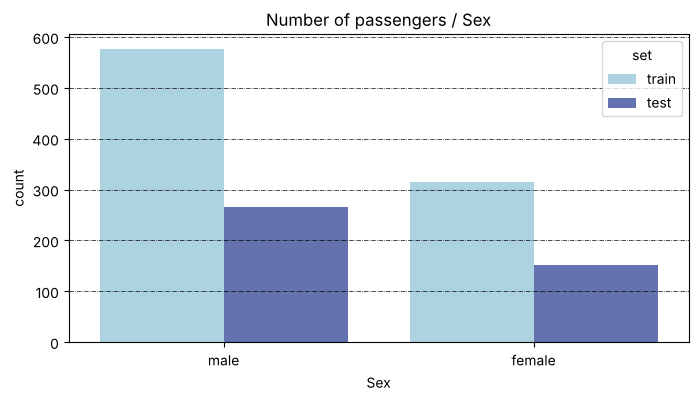

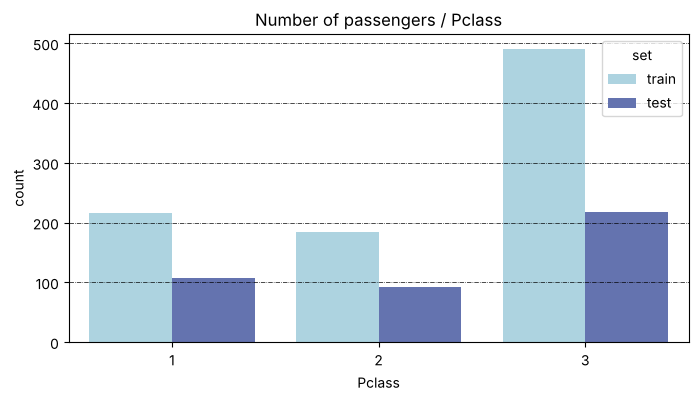

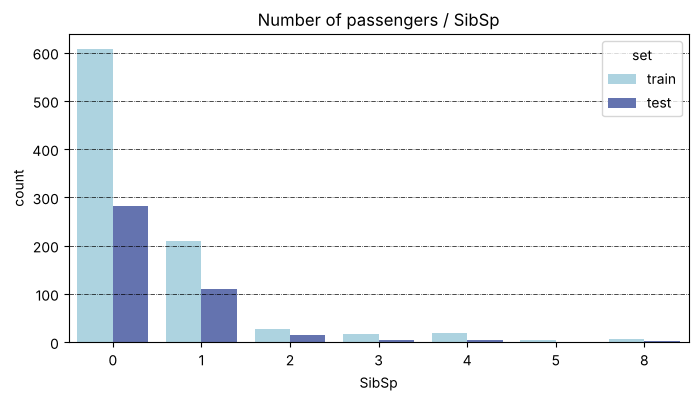

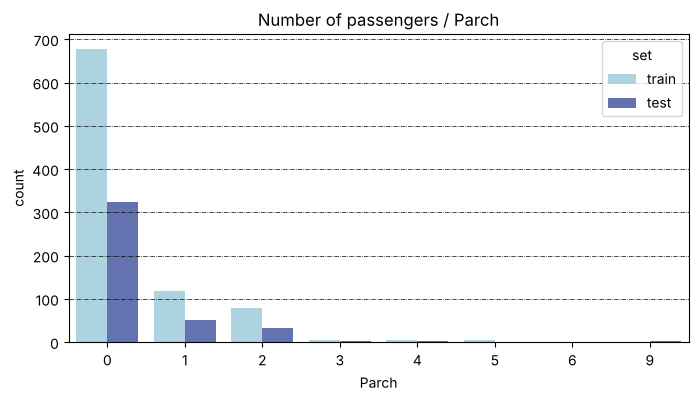

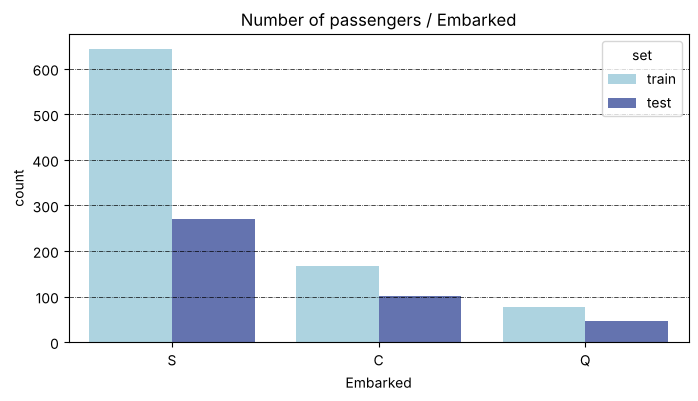

In [9]:
for feature in ["Sex", "Pclass", "SibSp", "Parch", "Embarked"]:
    plot_count_pairs(all_df, feature)

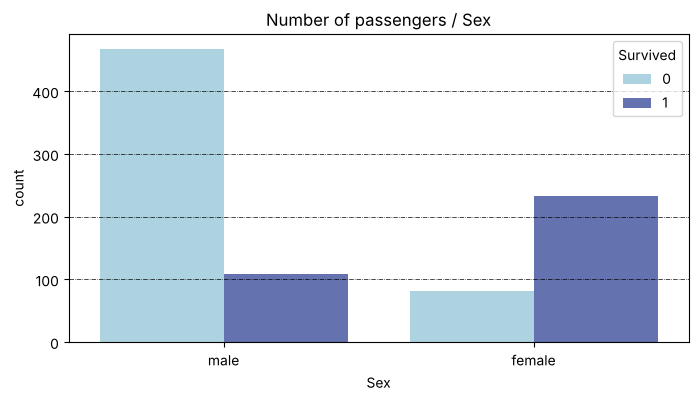

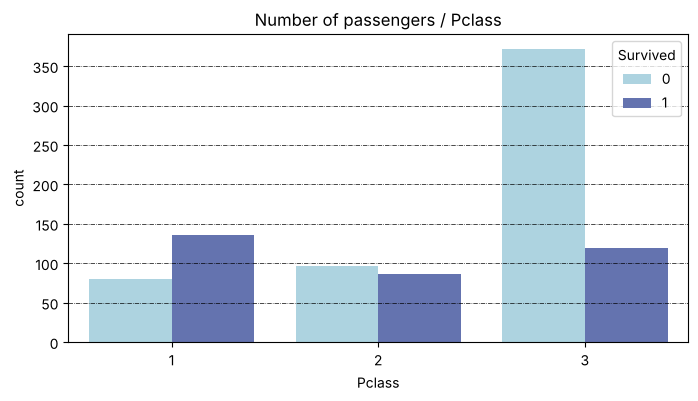

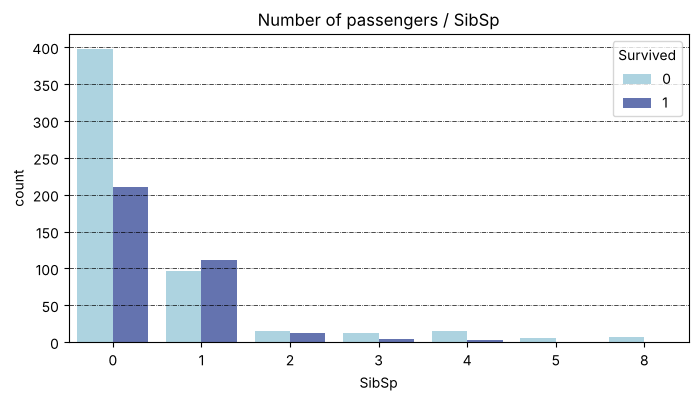

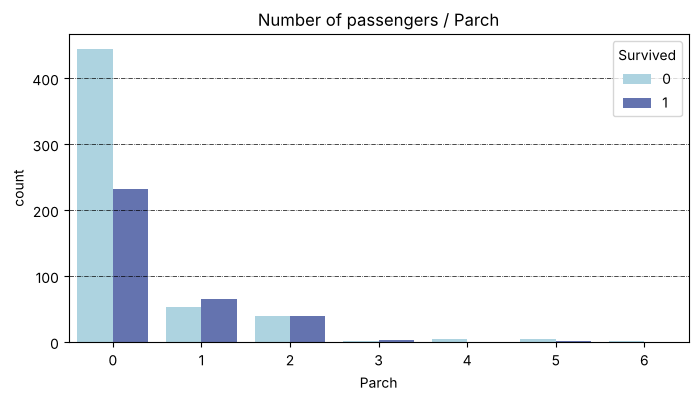

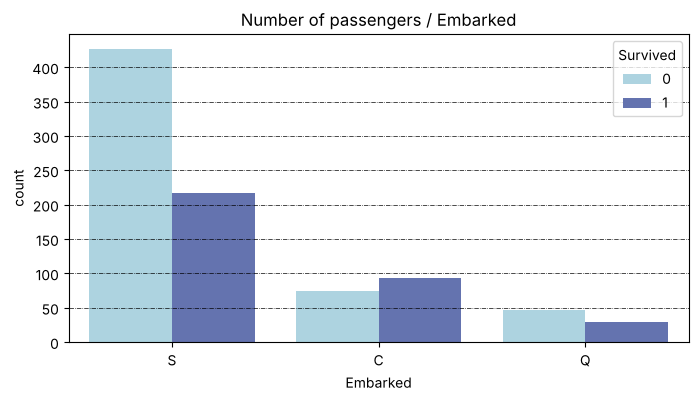

In [10]:
for feature in ["Sex", "Pclass", "SibSp", "Parch", "Embarked"]:
    plot_count_pairs(train_df, feature, hue="Survived")

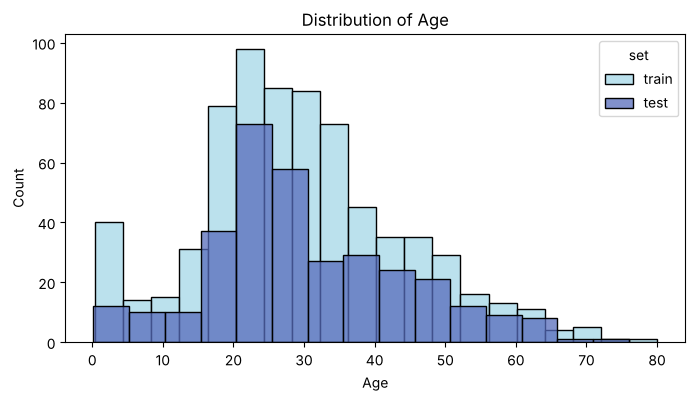

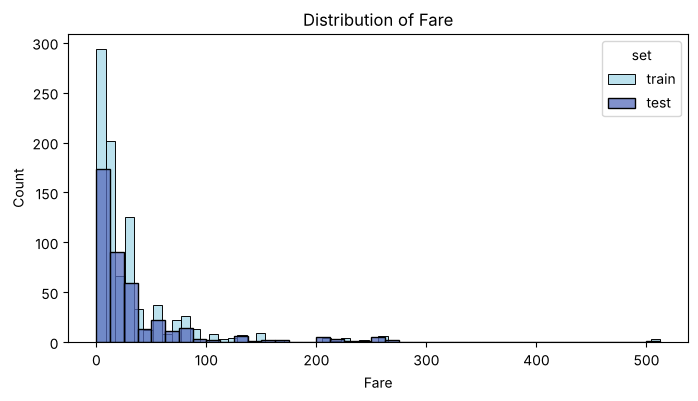

In [11]:
for feature in ["Age", "Fare"]:
    plot_distribution_pairs(all_df, feature)

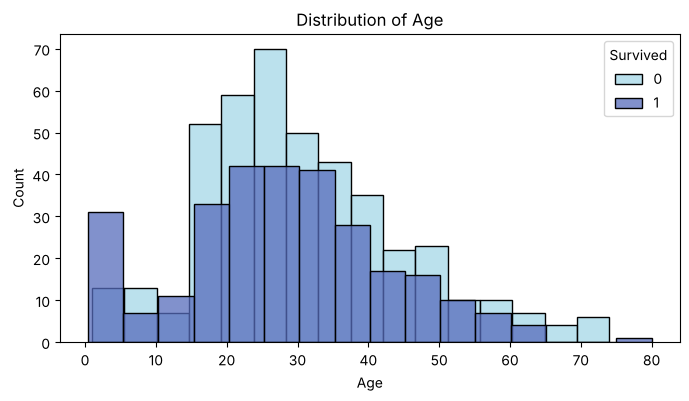

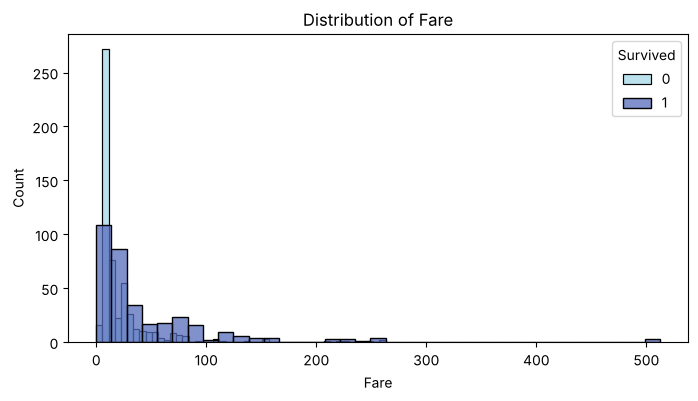

In [12]:
for feature in ["Age", "Fare"]:
    plot_distribution_pairs(train_df, feature, hue="Survived")

## Family size

Based on SibSp (siblings or spouse) and Parch (parents or children), we set the Family Size field.

In [13]:
all_df = add_family_size(all_df)
train_df = add_family_size(train_df)

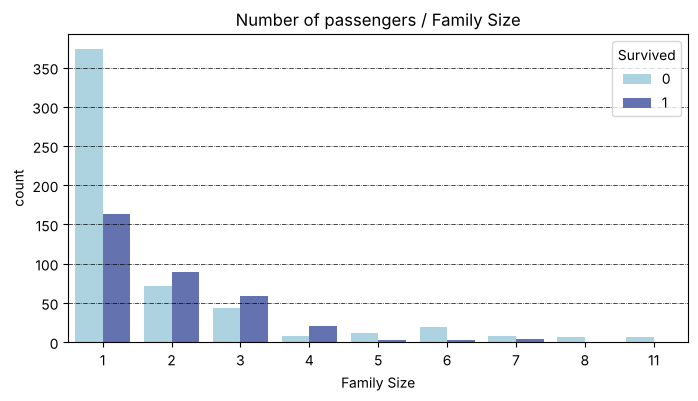

<Axes: title={'center': 'Number of passengers / Family Size'}, xlabel='Family Size', ylabel='count'>

In [14]:
plot_count_pairs(train_df, "Family Size", hue="Survived")

## Age interval

In [15]:
all_df = add_age_interval(all_df)
train_df = add_age_interval(train_df)
all_df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,set,Family Size,Age Interval
0,1,0.0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,train,2,1.0
1,2,1.0,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,train,2,2.0
2,3,1.0,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,train,1,1.0
3,4,1.0,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,train,2,2.0
4,5,0.0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,train,1,2.0


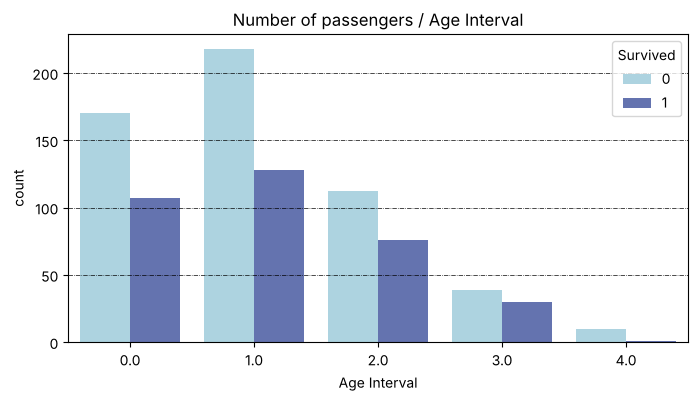

<Axes: title={'center': 'Number of passengers / Age Interval'}, xlabel='Age Interval', ylabel='count'>

In [16]:
plot_count_pairs(train_df, "Age Interval", hue="Survived")

## Fare interval

In [17]:
all_df = add_fare_interval(all_df)
train_df = add_fare_interval(train_df)

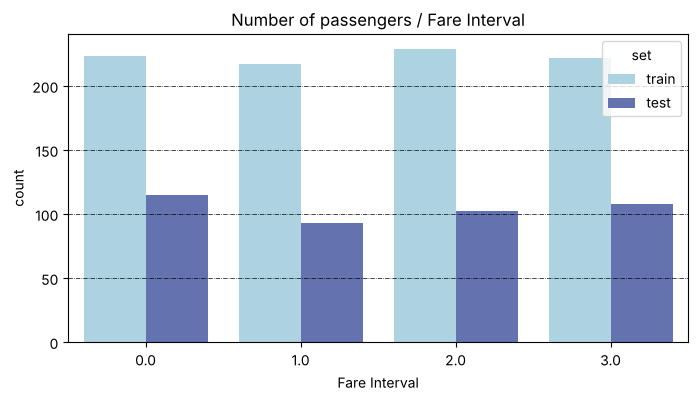

<Axes: title={'center': 'Number of passengers / Fare Interval'}, xlabel='Fare Interval', ylabel='count'>

In [18]:
plot_count_pairs(all_df, "Fare Interval")

Let's create a composed feature: Pclass + Sex.

In [19]:
train_df = add_sex_pclass(train_df)
all_df = add_sex_pclass(all_df)

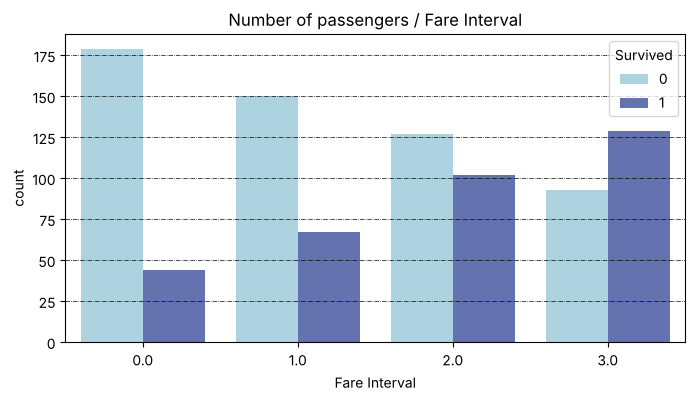

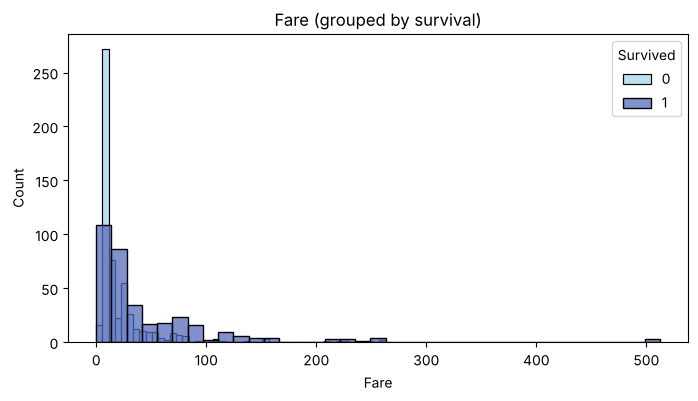

<Axes: title={'center': 'Fare (grouped by survival)'}, xlabel='Fare', ylabel='Count'>

In [20]:
plot_count_pairs(train_df, "Fare Interval", hue="Survived")
plot_distribution_pairs(train_df, "Fare", hue="Survived", title="Fare (grouped by survival)")

## Process names

When we process names, we extract:

- Family name - the first word (or words) before the comma
- Title - the word just after the comma
- Given name - the words following the title
- Maiden name - for married women, given between parentheses

The parsing logic is `parse_names` in `src/titanic/features.py`.

In [21]:
all_df = add_name_parts(all_df)
train_df = add_name_parts(train_df)
train_df[["Name", "Family Name", "Title", "Given Name", "Maiden Name"]].head()

,Name,Family Name,Title,Given Name,Maiden Name
0,"Braund, Mr. Owen Harris",Braund,Mr.,Owen Harris,NaN
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Cumings,Mrs.,John Bradley,Florence Briggs Thayer
2,"Heikkinen, Miss. Laina",Heikkinen,Miss.,Laina,NaN
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Futrelle,Mrs.,Jacques Heath,Lily May Peel
4,"Allen, Mr. William Henry",Allen,Mr.,William Henry,NaN


## Multivariate analysis

Let's look now at the interaction of multiple features.

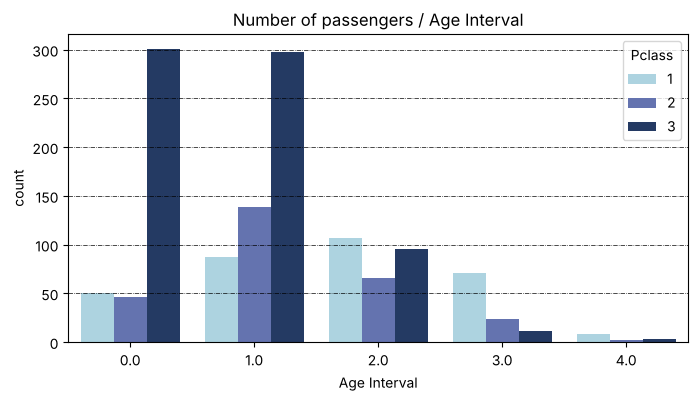

<Axes: title={'center': 'Number of passengers / Age Interval'}, xlabel='Age Interval', ylabel='count'>

In [22]:
plot_count_pairs(all_df, "Age Interval", hue="Pclass")

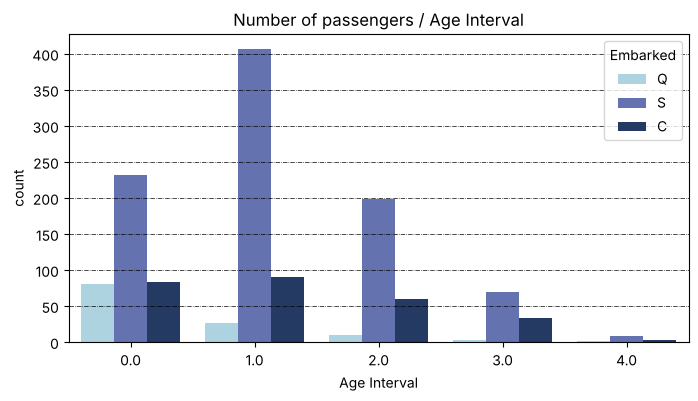

<Axes: title={'center': 'Number of passengers / Age Interval'}, xlabel='Age Interval', ylabel='count'>

In [23]:
plot_count_pairs(all_df, "Age Interval", hue="Embarked")

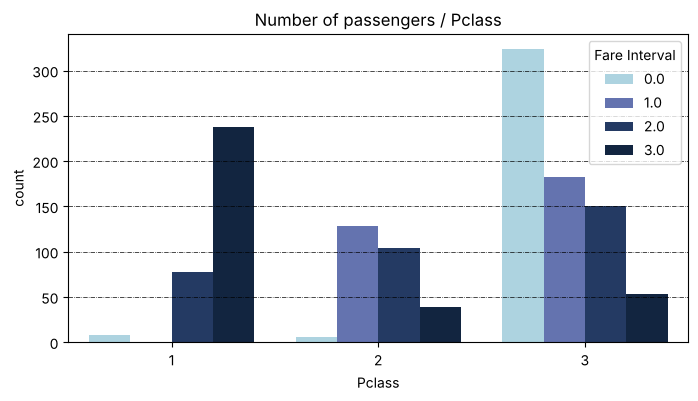

<Axes: title={'center': 'Number of passengers / Pclass'}, xlabel='Pclass', ylabel='count'>

In [24]:
plot_count_pairs(all_df, "Pclass", hue="Fare Interval")

### Few more engineered data

Let's create two more engineered features:
* Family size interval: Single, Small, Large
* Aggregated titles: Mr, Mrs, Master, Miss, and Rare

In [25]:
all_df = add_titles(add_family_type(all_df))
train_df = add_titles(add_family_type(train_df))

In [26]:
survival_rate_by(train_df, ["Titles", "Sex"])

,Titles,Sex,Survived
0,Master.,male,0.575000
1,Miss.,female,0.702703
2,Mr.,male,0.156673
3,Mrs.,female,0.793651
4,Rare,female,1.000000
5,Rare,male,0.250000


# Baseline model

## Feature engineering: Map categorical value to numerical values

In [27]:
train_df = encode_sex(train_df)
test_df = encode_sex(test_df)

Create train-validation split, fit a random forest on `Sex` and `Pclass`, and predict on both sets (predictors, target and model parameters are in `config.py`).

In [28]:
train, valid = split_data(train_df)
results = train_and_predict(train, valid)

# Evaluation

## Classification report for training data.

In [29]:
print(evaluate(results["train_y"], results["train_pred"]))

              precision    recall  f1-score   support

Not Survived       0.75      0.99      0.86       444
    Survived       0.96      0.47      0.63       268

    accuracy                           0.79       712
   macro avg       0.86      0.73      0.74       712
weighted avg       0.83      0.79      0.77       712



Classification report for validation data.

In [30]:
print(evaluate(results["valid_y"], results["valid_pred"]))

              precision    recall  f1-score   support

Not Survived       0.73      0.96      0.83       105
    Survived       0.90      0.49      0.63        74

    accuracy                           0.77       179
   macro avg       0.81      0.72      0.73       179
weighted avg       0.80      0.77      0.75       179

